In [1]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/MOR-Project"

%cd $PROJECT_DIR

!pip install -r requirements.txt

Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks/MOR-Project
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.7/139.7 MB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 8.8 MB/s eta 0:00:00


In [2]:
# ============================================================
# 1. PINN SETUP
# ============================================================

import os
import time
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# Reproducibility
SEED = 123

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch version : {torch.__version__}")
print(f"Device          : {device}")

if device.type == "cuda":
    print(f"GPU             : {torch.cuda.get_device_name(0)}")

PyTorch version : 2.11.0+cu130
Device          : cuda
GPU             : Tesla T4


In [3]:
# ============================================================
# 2. LOAD FOM DATASET
# ============================================================

DATA_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "fom"
)

POD_MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models",
    "pod_galerkin"
)

print("Data directory:")
print(DATA_DIR)

print("\nPOD model directory:")
print(POD_MODEL_DIR)

assert os.path.isdir(DATA_DIR), (
    f"Missing data directory: {DATA_DIR}"
)

assert os.path.isdir(POD_MODEL_DIR), (
    f"Missing POD model directory: {POD_MODEL_DIR}"
)

print("Directories found.")

train_parameters = np.load(
    os.path.join(
        DATA_DIR,
        "train_parameters.npy"
    )
)

train_snapshots = np.load(
    os.path.join(
        DATA_DIR,
        "train_snapshots.npy"
    )
)

train_metadata = np.load(
    os.path.join(
        DATA_DIR,
        "train_metadata.npy"
    ),
    allow_pickle=True
)

test_parameters = np.load(
    os.path.join(
        DATA_DIR,
        "test_parameters.npy"
    )
)

test_snapshots = np.load(
    os.path.join(
        DATA_DIR,
        "test_snapshots.npy"
    )
)

test_metadata = np.load(
    os.path.join(
        DATA_DIR,
        "test_metadata.npy"
    ),
    allow_pickle=True
)

# ------------------------------------------------------------
# Basic dataset information
# ------------------------------------------------------------

print("Training parameters :", train_parameters.shape)
print("Training snapshots  :", train_snapshots.shape)
print("Training metadata   :", train_metadata.shape)

print("Test parameters     :", test_parameters.shape)
print("Test snapshots      :", test_snapshots.shape)
print("Test metadata       :", test_metadata.shape)

Data directory:
/content/drive/MyDrive/Colab Notebooks/MOR-Project/data/fom

POD model directory:
/content/drive/MyDrive/Colab Notebooks/MOR-Project/models/pod_galerkin
Directories found.
Training parameters : (100, 2)
Training snapshots  : (100, 6761)
Training metadata   : (100,)
Test parameters     : (50, 2)
Test snapshots      : (50, 6761)
Test metadata       : (50,)


Parameter domain
--------------------------------------------------
mu0 ∈ [0.1, 10.0]
mu1 ∈ [1.0, 3.0]

Training set
--------------------------------------------------
mu0 range: [0.2238, 9.8909]
mu1 range: [1.0094, 2.9888]

Test set
--------------------------------------------------
mu0 range: [0.1860, 9.8740]
mu1 range: [1.0052, 2.9820]


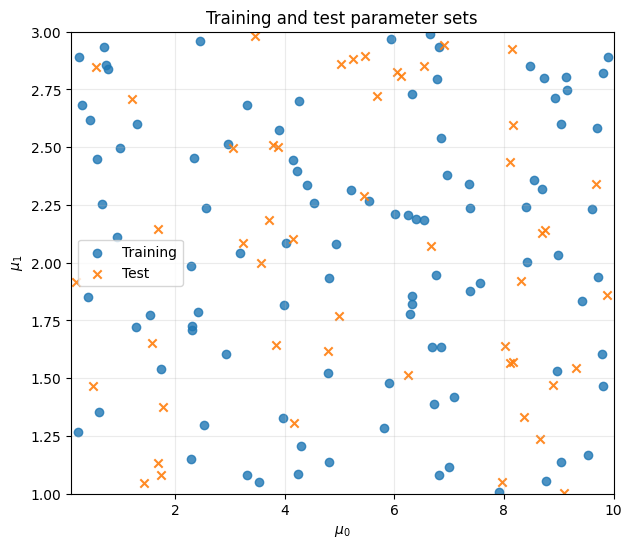

In [4]:
# ============================================================
# 3. INSPECT PARAMETER DATA
# ============================================================

MU0_MIN, MU0_MAX = 0.1, 10.0
MU1_MIN, MU1_MAX = 1.0, 3.0

print("Parameter domain")
print("-" * 50)
print(f"mu0 ∈ [{MU0_MIN}, {MU0_MAX}]")
print(f"mu1 ∈ [{MU1_MIN}, {MU1_MAX}]")

print("\nTraining set")
print("-" * 50)
print(
    f"mu0 range: "
    f"[{train_parameters[:, 0].min():.4f}, "
    f"{train_parameters[:, 0].max():.4f}]"
)
print(
    f"mu1 range: "
    f"[{train_parameters[:, 1].min():.4f}, "
    f"{train_parameters[:, 1].max():.4f}]"
)

print("\nTest set")
print("-" * 50)
print(
    f"mu0 range: "
    f"[{test_parameters[:, 0].min():.4f}, "
    f"{test_parameters[:, 0].max():.4f}]"
)
print(
    f"mu1 range: "
    f"[{test_parameters[:, 1].min():.4f}, "
    f"{test_parameters[:, 1].max():.4f}]"
)

# ============================================================
# 4. VISUALIZE TRAIN / TEST PARAMETER SETS
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    train_parameters[:, 0],
    train_parameters[:, 1],
    label="Training",
    alpha=0.8
)

ax.scatter(
    test_parameters[:, 0],
    test_parameters[:, 1],
    label="Test",
    marker="x",
    alpha=0.9
)

ax.set_xlabel(r"$\mu_0$")
ax.set_ylabel(r"$\mu_1$")
ax.set_title("Training and test parameter sets")
ax.set_xlim(MU0_MIN, MU0_MAX)
ax.set_ylim(MU1_MIN, MU1_MAX)
ax.grid(True, alpha=0.25)
ax.legend()

plt.show()

PINN mesh loaded
------------------------------------------------------------
Number of PINN nodes : 830
Coordinate shape     : (830, 2)
Velocity DOFs / comp : 2966
Pressure DOFs        : 829
Total FOM DOFs       : 6761

Coordinate ranges
------------------------------------------------------------
x: [0.000000, 1.000000]
y: [0.000000, 1.000000]


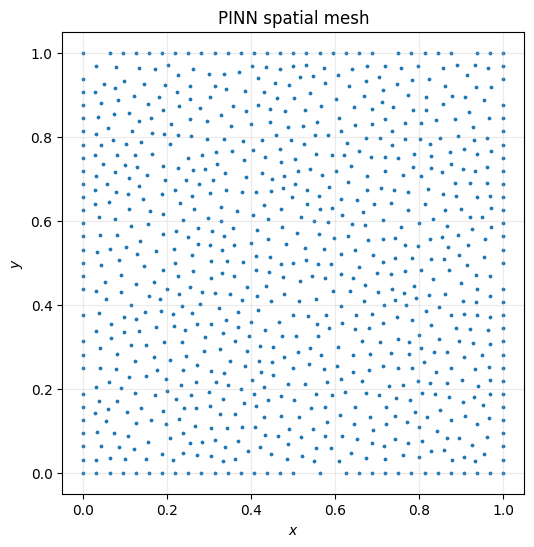

In [5]:
# ============================================================
# 5. LOAD PINN MESH
# ============================================================

pinn_coordinates = np.load(
    os.path.join(
        DATA_DIR,
        "pinn_coordinates.npy"
    )
)

pinn_pressure_indices = np.load(
    os.path.join(
        DATA_DIR,
        "pinn_pressure_indices.npy"
    )
)

pinn_velocity_indices = np.load(
    os.path.join(
        DATA_DIR,
        "pinn_velocity_indices.npy"
    )
)

mesh_info = np.load(
    os.path.join(
        DATA_DIR,
        "mesh_info.npy"
    ),
    allow_pickle=True
).item()


# ------------------------------------------------------------
# Extract basic mesh information
# ------------------------------------------------------------

n_pinn_nodes = pinn_coordinates.shape[0]

speed_n_dofs = mesh_info["speed_n_dofs"]
pressure_n_dofs = mesh_info["pressure_n_dofs"]
total_dofs = mesh_info["total_dofs"]


# ------------------------------------------------------------
# Print information
# ------------------------------------------------------------

print("PINN mesh loaded")
print("-" * 60)

print(f"Number of PINN nodes : {n_pinn_nodes}")
print(f"Coordinate shape     : {pinn_coordinates.shape}")

print(f"Velocity DOFs / comp : {speed_n_dofs}")
print(f"Pressure DOFs        : {pressure_n_dofs}")
print(f"Total FOM DOFs       : {total_dofs}")

print()
print("Coordinate ranges")
print("-" * 60)

print(
    f"x: [{pinn_coordinates[:, 0].min():.6f}, "
    f"{pinn_coordinates[:, 0].max():.6f}]"
)

print(
    f"y: [{pinn_coordinates[:, 1].min():.6f}, "
    f"{pinn_coordinates[:, 1].max():.6f}]"
)

# ============================================================
# 6. VERIFY PINN MESH
# ============================================================

x_mesh = pinn_coordinates[:, 0]
y_mesh = pinn_coordinates[:, 1]

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    x_mesh,
    y_mesh,
    s=3
)

ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("PINN spatial mesh")
ax.set_aspect("equal")
ax.grid(True, alpha=0.25)

plt.show()

In [6]:
# ============================================================
# 7. EXTRACT FOM FIELDS FROM SNAPSHOTS
# ============================================================

# Velocity x-component
train_ux = train_snapshots[
    :,
    pinn_velocity_indices
]

test_ux = test_snapshots[
    :,
    pinn_velocity_indices
]


# Velocity y-component
train_uy = train_snapshots[
    :,
    speed_n_dofs + pinn_velocity_indices
]

test_uy = test_snapshots[
    :,
    speed_n_dofs + pinn_velocity_indices
]


# Pressure
train_p = train_snapshots[
    :,
    2 * speed_n_dofs + pinn_pressure_indices
]

test_p = test_snapshots[
    :,
    2 * speed_n_dofs + pinn_pressure_indices
]


print("FOM fields extracted")
print("-" * 60)

print("Training:")
print("  ux :", train_ux.shape)
print("  uy :", train_uy.shape)
print("  p  :", train_p.shape)

print("\nTest:")
print("  ux :", test_ux.shape)
print("  uy :", test_uy.shape)
print("  p  :", test_p.shape)

FOM fields extracted
------------------------------------------------------------
Training:
  ux : (100, 830)
  uy : (100, 830)
  p  : (100, 830)

Test:
  ux : (50, 830)
  uy : (50, 830)
  p  : (50, 830)


All FOM field consistency checks passed.


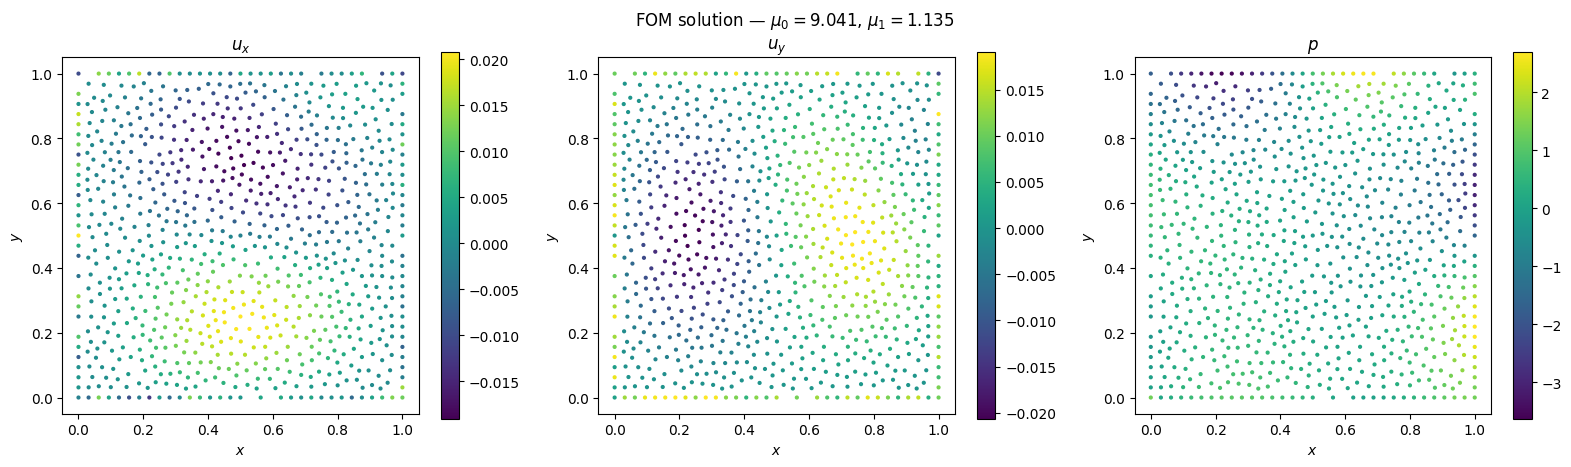

In [7]:
# ============================================================
# 8. CHECK FOM FIELD CONSISTENCY
# ============================================================

N_train = train_parameters.shape[0]
N_test = test_parameters.shape[0]
N_nodes = pinn_coordinates.shape[0]

assert train_ux.shape == (N_train, N_nodes)
assert train_uy.shape == (N_train, N_nodes)
assert train_p.shape == (N_train, N_nodes)

assert test_ux.shape == (N_test, N_nodes)
assert test_uy.shape == (N_test, N_nodes)
assert test_p.shape == (N_test, N_nodes)

assert np.isfinite(train_ux).all()
assert np.isfinite(train_uy).all()
assert np.isfinite(train_p).all()

assert np.isfinite(test_ux).all()
assert np.isfinite(test_uy).all()
assert np.isfinite(test_p).all()

print("All FOM field consistency checks passed.")

# ============================================================
# 9. VISUALIZE ONE FOM SNAPSHOT
# ============================================================

snapshot_id = 0

x_mesh = pinn_coordinates[:, 0]
y_mesh = pinn_coordinates[:, 1]

mu0 = train_parameters[snapshot_id, 0]
mu1 = train_parameters[snapshot_id, 1]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.5)
)

fields = [
    train_ux[snapshot_id],
    train_uy[snapshot_id],
    train_p[snapshot_id]
]

titles = [
    r"$u_x$",
    r"$u_y$",
    r"$p$"
]

for ax, field, title in zip(
    axes,
    fields,
    titles
):
    scatter = ax.scatter(
        x_mesh,
        y_mesh,
        c=field,
        s=4
    )

    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_title(title)
    ax.set_aspect("equal")

    fig.colorbar(
        scatter,
        ax=ax
    )

fig.suptitle(
    f"FOM solution — "
    f"$\\mu_0={mu0:.3f}$, "
    f"$\\mu_1={mu1:.3f}$"
)

plt.tight_layout()
plt.show()

In [9]:
# ============================================================
# 10. DEFINE THE PARAMETRIC PINN
# ============================================================

# ------------------------------------------------------------
# PINN input/output definition
# ------------------------------------------------------------
#
# Input:
#     (x, y, mu0, mu1)
#
# Output:
#     (ux, uy, p)
#
# ------------------------------------------------------------

# Spatial domain
X_MIN, X_MAX = 0.0, 1.0
Y_MIN, Y_MAX = 0.0, 1.0

# Parameter domain
MU0_MIN, MU0_MAX = 0.1, 10.0
MU1_MIN, MU1_MAX = 1.0, 3.0


def normalize_inputs(x, y, mu0, mu1):
    """
    Normalize all four inputs to approximately [-1, 1].
    """

    x_norm = (
        2.0 * (x - X_MIN)
        / (X_MAX - X_MIN)
        - 1.0
    )

    y_norm = (
        2.0 * (y - Y_MIN)
        / (Y_MAX - Y_MIN)
        - 1.0
    )

    mu0_norm = (
        2.0 * (mu0 - MU0_MIN)
        / (MU0_MAX - MU0_MIN)
        - 1.0
    )

    mu1_norm = (
        2.0 * (mu1 - MU1_MIN)
        / (MU1_MAX - MU1_MIN)
        - 1.0
    )

    return (
        x_norm,
        y_norm,
        mu0_norm,
        mu1_norm
    )


# ------------------------------------------------------------
# Network architecture
# ------------------------------------------------------------

class PINN(nn.Module):

    def __init__(
        self,
        layers=(6, 256,256,256, 256, 256, 256, 3)
    ):
        super().__init__()

        network = []

        for i in range(len(layers) - 2):
            network.append(
                nn.Linear(
                    layers[i],
                    layers[i + 1]
                )
            )
            network.append(nn.Tanh())

        network.append(
            nn.Linear(
                layers[-2],
                layers[-1]
            )
        )

        self.network = nn.Sequential(*network)

    def forward(self, x, y, mu0, mu1):

        x_norm, y_norm, mu0_norm, mu1_norm = (
            normalize_inputs(
                x,
                y,
                mu0,
                mu1
            )
        )

        inputs = torch.cat(
            [
                x_norm,
                y_norm,
                mu0_norm,
                mu1_norm
            ],
            dim=1
        )

        return self.network(inputs)


# ------------------------------------------------------------
# Create model
# ------------------------------------------------------------

model = PINN().to(device)


# ------------------------------------------------------------
# Inspect model
# ------------------------------------------------------------

print(model)

print()
print("-" * 60)
print("Number of trainable parameters:",
      sum(
          p.numel()
          for p in model.parameters()
          if p.requires_grad
      ))

# ------------------------------------------------------------
# Sanity check: forward pass
# ------------------------------------------------------------

x_test = torch.tensor(
    [[0.0], [0.5], [1.0]],
    dtype=torch.float32,
    device=device
)

y_test = torch.tensor(
    [[0.0], [0.5], [1.0]],
    dtype=torch.float32,
    device=device
)

mu0_test = torch.tensor(
    [[MU0_MIN], [5.0], [MU0_MAX]],
    dtype=torch.float32,
    device=device
)

mu1_test = torch.tensor(
    [[MU1_MIN], [2.0], [MU1_MAX]],
    dtype=torch.float32,
    device=device
)

with torch.no_grad():
    output_test = model(
        x_test,
        y_test,
        mu0_test,
        mu1_test
    )

print("Output shape:", output_test.shape)
print("Expected    :", "(3, 3)")

PINN(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=256, bias=True)
    (1): Tanh()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): Tanh()
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): Tanh()
    (6): Linear(in_features=256, out_features=256, bias=True)
    (7): Tanh()
    (8): Linear(in_features=256, out_features=256, bias=True)
    (9): Tanh()
    (10): Linear(in_features=256, out_features=256, bias=True)
    (11): Tanh()
    (12): Linear(in_features=256, out_features=3, bias=True)
  )
)

------------------------------------------------------------
Number of trainable parameters: 331011
Output shape: torch.Size([3, 3])
Expected    : (3, 3)


In [10]:
# ============================================================
# 11. NAVIER-STOKES SOURCE TERM
# ============================================================

PI = torch.pi


def source_term(x, y, mu1):
    """
    Compute the two components of the forcing term

        f = (f1, f2)

    for the parametrized Navier-Stokes problem.
    """

    f1 = (
        -(
            mu1**3 * PI**2
            * torch.cos(mu1**2 * PI * x)
            - mu1**2 * PI**2
        )
        * torch.sin(mu1 * PI * y)
        * torch.cos(mu1 * PI * y)

        + mu1 * PI
        * torch.cos(mu1 * PI * x)
        * torch.cos(mu1 * PI * y)
    )

    f2 = (
        -(
            -mu1**3 * PI**2
            * torch.cos(mu1**2 * PI * y)
            + mu1**2 * PI**2
        )
        * torch.sin(mu1 * PI * x)
        * torch.cos(mu1 * PI * x)

        - mu1 * PI
        * torch.sin(mu1 * PI * x)
        * torch.sin(mu1 * PI * y)
    )

    return f1, f2

# ------------------------------------------------------------
# Sanity check
# ------------------------------------------------------------

x_source = torch.tensor(
    [[0.25], [0.5]],
    dtype=torch.float32,
    device=device
)

y_source = torch.tensor(
    [[0.25], [0.75]],
    dtype=torch.float32,
    device=device
)

mu1_source = torch.tensor(
    [[1.0], [2.0]],
    dtype=torch.float32,
    device=device
)

f1_test, f2_test = source_term(
    x_source,
    y_source,
    mu1_source
)

print("f1 shape:", f1_test.shape)
print("f2 shape:", f2_test.shape)

print("\nf1:")
print(f1_test)

print("\nf2:")
print(f2_test)

f1 shape: torch.Size([2, 1])
f2 shape: torch.Size([2, 1])

f1:
tensor([[3.0162e+00],
        [3.9585e-07]], device='cuda:0')

f2:
tensor([[-3.0162e+00],
        [-1.0903e-05]], device='cuda:0')


In [11]:
# ============================================================
# 12. NAVIER-STOKES PDE RESIDUALS
# ============================================================

def gradient(output, input_tensor):
    """
    Compute d(output) / d(input_tensor) using PyTorch
    automatic differentiation.

    create_graph=True is required because we will later
    differentiate first derivatives again to obtain
    second derivatives.
    """

    return torch.autograd.grad(
        outputs=output,
        inputs=input_tensor,
        grad_outputs=torch.ones_like(output),
        create_graph=True,
        retain_graph=True
    )[0]


def pde_residuals(model, x, y, mu0, mu1):
    """
    Compute the three Navier-Stokes residuals:

        Rx   : x-momentum equation
        Ry   : y-momentum equation
        Rdiv : incompressibility condition

    Inputs
    ------
    x, y, mu0, mu1 : tensors of shape (N, 1)

    Returns
    -------
    Rx, Ry, Rdiv : tensors of shape (N, 1)
    """

    # --------------------------------------------------------
    # Network prediction
    # --------------------------------------------------------

    prediction = model(
        x,
        y,
        mu0,
        mu1
    )

    ux = prediction[:, 0:1]
    uy = prediction[:, 1:2]
    p  = prediction[:, 2:3]


    # --------------------------------------------------------
    # First derivatives
    # --------------------------------------------------------

    ux_x = gradient(ux, x)
    ux_y = gradient(ux, y)

    uy_x = gradient(uy, x)
    uy_y = gradient(uy, y)

    p_x = gradient(p, x)
    p_y = gradient(p, y)


    # --------------------------------------------------------
    # Second derivatives of velocity
    # --------------------------------------------------------

    ux_xx = gradient(ux_x, x)
    ux_yy = gradient(ux_y, y)

    uy_xx = gradient(uy_x, x)
    uy_yy = gradient(uy_y, y)


    # --------------------------------------------------------
    # Source term
    # --------------------------------------------------------

    f1, f2 = source_term(
        x,
        y,
        mu1
    )


    # --------------------------------------------------------
    # Momentum residuals
    # --------------------------------------------------------

    Rx = (
        -mu0 * (ux_xx + ux_yy)
        + ux * ux_x
        + uy * ux_y
        + p_x
        - f1
    )

    Ry = (
        -mu0 * (uy_xx + uy_yy)
        + ux * uy_x
        + uy * uy_y
        + p_y
        - f2
    )


    # --------------------------------------------------------
    # Incompressibility residual
    # --------------------------------------------------------

    Rdiv = ux_x + uy_y


    return Rx, Ry, Rdiv

# ------------------------------------------------------------
# Sanity check: PDE residual evaluation
# ------------------------------------------------------------

N_test_points = 32

x_collocation = torch.rand(
    N_test_points,
    1,
    device=device,
    requires_grad=True
)

y_collocation = torch.rand(
    N_test_points,
    1,
    device=device,
    requires_grad=True
)

mu0_collocation = (
    MU0_MIN
    + (MU0_MAX - MU0_MIN)
    * torch.rand(
        N_test_points,
        1,
        device=device
    )
)

mu1_collocation = (
    MU1_MIN
    + (MU1_MAX - MU1_MIN)
    * torch.rand(
        N_test_points,
        1,
        device=device
    )
)


Rx, Ry, Rdiv = pde_residuals(
    model,
    x_collocation,
    y_collocation,
    mu0_collocation,
    mu1_collocation
)


print("Residual shapes")
print("-" * 60)
print("Rx   :", Rx.shape)
print("Ry   :", Ry.shape)
print("Rdiv :", Rdiv.shape)

print("\nFinite-value check")
print("-" * 60)
print("Rx   :", torch.isfinite(Rx).all().item())
print("Ry   :", torch.isfinite(Ry).all().item())
print("Rdiv :", torch.isfinite(Rdiv).all().item())

Residual shapes
------------------------------------------------------------
Rx   : torch.Size([32, 1])
Ry   : torch.Size([32, 1])
Rdiv : torch.Size([32, 1])

Finite-value check
------------------------------------------------------------
Rx   : True
Ry   : True
Rdiv : True


In [12]:
# ============================================================
# 13. COLLOCATION-POINT SAMPLING
# ============================================================

def sample_interior(
    n_points,
    device=device
):
    """
    Sample points in the interior of

        Omega x P

    where

        Omega = [0,1] x [0,1]
        P     = [0.1,10] x [1,3]

    x and y require gradients because the PDE residuals
    contain first and second spatial derivatives.
    """

    x = torch.rand(
        n_points,
        1,
        device=device,
        requires_grad=True
    )

    y = torch.rand(
        n_points,
        1,
        device=device,
        requires_grad=True
    )

    mu0 = (
        MU0_MIN
        + (MU0_MAX - MU0_MIN)
        * torch.rand(
            n_points,
            1,
            device=device
        )
    )

    mu1 = (
        MU1_MIN
        + (MU1_MAX - MU1_MIN)
        * torch.rand(
            n_points,
            1,
            device=device
        )
    )

    return x, y, mu0, mu1


def sample_boundary(
    n_points,
    device=device
):
    """
    Sample points uniformly on all four boundaries.

    The number of points is distributed as evenly as
    possible over the four sides.

    Boundary condition:
        ux = uy = 0
    """

    # Number of points per side
    n_side = n_points // 4

    # Remaining points, if n_points is not divisible by 4
    remainder = n_points - 4 * n_side

    side_counts = [
        n_side + (1 if i < remainder else 0)
        for i in range(4)
    ]

    boundary_points = []

    for side, n in enumerate(side_counts):

        t = torch.rand(
            n,
            1,
            device=device
        )

        if side == 0:
            # y = 0
            x = t
            y = torch.zeros_like(t)

        elif side == 1:
            # y = 1
            x = t
            y = torch.ones_like(t)

        elif side == 2:
            # x = 0
            x = torch.zeros_like(t)
            y = t

        else:
            # x = 1
            x = torch.ones_like(t)
            y = t

        boundary_points.append(
            torch.cat([x, y], dim=1)
        )

    xy = torch.cat(
        boundary_points,
        dim=0
    )

    # Random parameter values on the boundary.
    mu0 = (
        MU0_MIN
        + (MU0_MAX - MU0_MIN)
        * torch.rand(
            xy.shape[0],
            1,
            device=device
        )
    )

    mu1 = (
        MU1_MIN
        + (MU1_MAX - MU1_MIN)
        * torch.rand(
            xy.shape[0],
            1,
            device=device
        )
    )

    return (
        xy[:, 0:1],
        xy[:, 1:2],
        mu0,
        mu1
    )


def sample_pressure_gauge(
    n_points,
    device=device
):
    """
    Sample parameter values at the pressure reference point

        (x,y) = (0,0)

    and enforce

        p(0,0,mu0,mu1) = 0.
    """

    x = torch.zeros(
        n_points,
        1,
        device=device
    )

    y = torch.zeros(
        n_points,
        1,
        device=device
    )

    mu0 = (
        MU0_MIN
        + (MU0_MAX - MU0_MIN)
        * torch.rand(
            n_points,
            1,
            device=device
        )
    )

    mu1 = (
        MU1_MIN
        + (MU1_MAX - MU1_MIN)
        * torch.rand(
            n_points,
            1,
            device=device
        )
    )

    return x, y, mu0, mu1

# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

N_INTERIOR_TEST = 100
N_BOUNDARY_TEST = 40
N_GAUGE_TEST = 10

x_i, y_i, mu0_i, mu1_i = sample_interior(
    N_INTERIOR_TEST
)

x_b, y_b, mu0_b, mu1_b = sample_boundary(
    N_BOUNDARY_TEST
)

x_g, y_g, mu0_g, mu1_g = sample_pressure_gauge(
    N_GAUGE_TEST
)


print("Interior points")
print("-" * 60)
print("x   :", x_i.shape)
print("y   :", y_i.shape)
print("mu0 :", mu0_i.shape)
print("mu1 :", mu1_i.shape)

print("\nBoundary points")
print("-" * 60)
print("x   :", x_b.shape)
print("y   :", y_b.shape)
print("mu0 :", mu0_b.shape)
print("mu1 :", mu1_b.shape)

print("\nPressure-gauge points")
print("-" * 60)
print("x   :", x_g.shape)
print("y   :", y_g.shape)
print("mu0 :", mu0_g.shape)
print("mu1 :", mu1_g.shape)


# Check parameter ranges
assert mu0_i.min() >= MU0_MIN
assert mu0_i.max() <= MU0_MAX
assert mu1_i.min() >= MU1_MIN
assert mu1_i.max() <= MU1_MAX

# Check boundary coordinates
assert torch.all(
    (x_b == 0)
    | (x_b == 1)
    | (y_b == 0)
    | (y_b == 1)
)

# Check gauge coordinates
assert torch.all(x_g == 0)
assert torch.all(y_g == 0)

print("\nAll sampling checks passed.")

Interior points
------------------------------------------------------------
x   : torch.Size([100, 1])
y   : torch.Size([100, 1])
mu0 : torch.Size([100, 1])
mu1 : torch.Size([100, 1])

Boundary points
------------------------------------------------------------
x   : torch.Size([40, 1])
y   : torch.Size([40, 1])
mu0 : torch.Size([40, 1])
mu1 : torch.Size([40, 1])

Pressure-gauge points
------------------------------------------------------------
x   : torch.Size([10, 1])
y   : torch.Size([10, 1])
mu0 : torch.Size([10, 1])
mu1 : torch.Size([10, 1])

All sampling checks passed.


In [13]:
# ============================================================
# 14. PURE PINN LOSS
# ============================================================

def compute_pinn_losses(
    model,
    n_interior=2000,
    n_boundary=500,
    n_gauge=20,
):
    """
    Compute the individual loss terms of the pure PINN.

    Loss components:

        L_momentum
        L_divergence
        L_boundary
        L_pressure

    No FOM data are used here.
    """

    # --------------------------------------------------------
    # 1. Interior collocation points
    # --------------------------------------------------------

    x_i, y_i, mu0_i, mu1_i = sample_interior(
        n_interior
    )

    Rx, Ry, Rdiv = pde_residuals(
        model,
        x_i,
        y_i,
        mu0_i,
        mu1_i
    )

    zero_interior = torch.zeros_like(Rx)

    loss_momentum = (
        torch.mean(Rx**2)
        +
        torch.mean(Ry**2)
    )

    loss_divergence = torch.mean(
        Rdiv**2
    )


    # --------------------------------------------------------
    # 2. Boundary condition
    # --------------------------------------------------------

    x_b, y_b, mu0_b, mu1_b = sample_boundary(
        n_boundary
    )

    prediction_b = model(
        x_b,
        y_b,
        mu0_b,
        mu1_b
    )

    ux_b = prediction_b[:, 0:1]
    uy_b = prediction_b[:, 1:2]

    zero_boundary = torch.zeros_like(ux_b)

    loss_boundary = (
        torch.mean(ux_b**2)
        +
        torch.mean(uy_b**2)
    )


    # --------------------------------------------------------
    # 3. Pressure gauge
    # --------------------------------------------------------

    x_g, y_g, mu0_g, mu1_g = sample_pressure_gauge(
        n_gauge
    )

    prediction_g = model(
        x_g,
        y_g,
        mu0_g,
        mu1_g
    )

    p_g = prediction_g[:, 2:3]

    #loss_pressure = torch.mean(
       # p_g**2
   # )
    loss_pressure = torch.tensor(0.0, device=device)


    return {
        "momentum": loss_momentum,
        "divergence": loss_divergence,
        "boundary": loss_boundary,
        "pressure": loss_pressure,
    }


# ------------------------------------------------------------
# Initial loss evaluation
# ------------------------------------------------------------

losses = compute_pinn_losses(model)

print("Initial PINN losses")
print("-" * 60)

for name, value in losses.items():
    print(
        f"{name:12s}: {value.item():.6e}"
    )

# ------------------------------------------------------------
# Total pure-PINN loss
# ------------------------------------------------------------

def total_pinn_loss(
    model,
    n_interior=2000,
    n_boundary=500,
    n_gauge=20,
):
    losses = compute_pinn_losses(
        model,
        n_interior=n_interior,
        n_boundary=n_boundary,
        n_gauge=n_gauge,
    )

    total = sum(losses.values())

    return total, losses


total_loss, losses = total_pinn_loss(model)

print("\nTotal PINN loss")
print("-" * 60)
print(f"{total_loss.item():.6e}")

Initial PINN losses
------------------------------------------------------------
momentum    : 2.440508e+03
divergence  : 1.676207e-04
boundary    : 2.078814e-03
pressure    : 0.000000e+00

Total PINN loss
------------------------------------------------------------
2.469000e+03


In [14]:
# ------------------------------------------------------------
# Momentum residual scaling
# ------------------------------------------------------------

def momentum_scale(mu1):
    """
    Characteristic scale for the momentum residual.

    The supplied PINN implementation uses:
        mu1^2 * pi^2
    """

    return mu1**2 * torch.pi**2

# ============================================================
# 14. PURE PINN LOSS
# ============================================================

def compute_pinn_losses(
    model,
    n_interior=2000,
    n_boundary=500,
    n_gauge=20,
):

    # --------------------------------------------------------
    # Interior collocation points
    # --------------------------------------------------------

    x_i, y_i, mu0_i, mu1_i = sample_interior(
        n_interior
    )

    Rx, Ry, Rdiv = pde_residuals(
        model,
        x_i,
        y_i,
        mu0_i,
        mu1_i
    )

    # Characteristic forcing/momentum scale
    scale = momentum_scale(mu1_i).detach()

    Rx_scaled = Rx / scale
    Ry_scaled = Ry / scale

    loss_momentum = (
        torch.mean(Rx_scaled**2)
        +
        torch.mean(Ry_scaled**2)
    )

    loss_divergence = torch.mean(
        Rdiv**2
    )


    # --------------------------------------------------------
    # Boundary condition
    # --------------------------------------------------------

    x_b, y_b, mu0_b, mu1_b = sample_boundary(
        n_boundary
    )

    prediction_b = model(
        x_b,
        y_b,
        mu0_b,
        mu1_b
    )

    ux_b = prediction_b[:, 0:1]
    uy_b = prediction_b[:, 1:2]

    loss_boundary = (
        torch.mean(ux_b**2)
        +
        torch.mean(uy_b**2)
    )


    # --------------------------------------------------------
    # Pressure gauge
    # --------------------------------------------------------

    x_g, y_g, mu0_g, mu1_g = sample_pressure_gauge(
        n_gauge
    )

    prediction_g = model(
        x_g,
        y_g,
        mu0_g,
        mu1_g
    )

    p_g = prediction_g[:, 2:3]

    loss_pressure = torch.mean(
        p_g**2
    )


    return {
        "momentum": loss_momentum,
        "divergence": loss_divergence,
        "boundary": loss_boundary,
        "pressure": loss_pressure,
    }

total_loss, losses = total_pinn_loss(model)

print("Initial PINN losses")
print("-" * 60)

for name, value in losses.items():
    print(f"{name:12s}: {value.item():.6e}")

print()
print("Total PINN loss")
print("-" * 60)
print(f"{total_loss.item():.6e}")

Initial PINN losses
------------------------------------------------------------
momentum    : 7.606745e-01
divergence  : 1.558522e-04
boundary    : 2.077389e-03
pressure    : 1.634030e-03

Total PINN loss
------------------------------------------------------------
7.645417e-01


Starting boundary/gauge pretraining...
------------------------------------------------------------
------------------------------------------------------------
Pretraining completed in 0.00 s


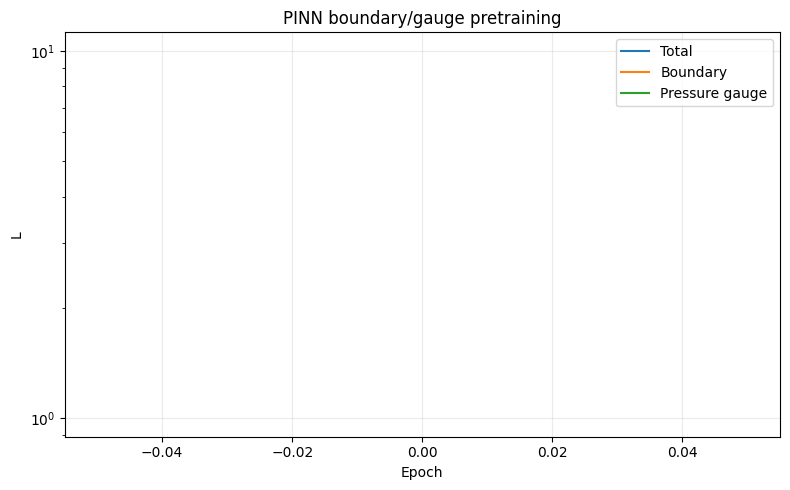

In [15]:
# ============================================================
# 15. PRETRAIN BOUNDARY CONDITION AND PRESSURE GAUGE
# ============================================================

# ------------------------------------------------------------
# Pretraining settings
# ------------------------------------------------------------

N_PRETRAIN = 0
N_BOUNDARY = 500
N_GAUGE = 20

LR_PRETRAIN = 1e-3


# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer_pretrain = torch.optim.Adam(
    model.parameters(),
    lr=LR_PRETRAIN
)


# ------------------------------------------------------------
# History
# ------------------------------------------------------------

pretrain_history = {
    "total": [],
    "boundary": [],
    "pressure": [],
}


# ------------------------------------------------------------
# Pretraining loop
# ------------------------------------------------------------

print("Starting boundary/gauge pretraining...")
print("-" * 60)

t_start = time.time()

for epoch in range(1, N_PRETRAIN + 1):

    optimizer_pretrain.zero_grad()


    # ========================================================
    # Boundary condition
    # ========================================================

    x_b, y_b, mu0_b, mu1_b = sample_boundary(
        N_BOUNDARY
    )

    prediction_b = model(
        x_b,
        y_b,
        mu0_b,
        mu1_b
    )

    ux_b = prediction_b[:, 0:1]
    uy_b = prediction_b[:, 1:2]

    loss_boundary = (
        torch.mean(ux_b**2)
        +
        torch.mean(uy_b**2)
    )


    # ========================================================
    # Pressure gauge
    # ========================================================

    x_g, y_g, mu0_g, mu1_g = sample_pressure_gauge(
        N_GAUGE
    )

    prediction_g = model(
        x_g,
        y_g,
        mu0_g,
        mu1_g
    )

    p_g = prediction_g[:, 2:3]

    loss_pressure = torch.mean(
        p_g**2
    )


    # ========================================================
    # Total pretraining loss
    # ========================================================

    loss = (
        loss_boundary
        + loss_pressure
    )


    # ========================================================
    # Backpropagation
    # ========================================================

    loss.backward()

    optimizer_pretrain.step()


    # ========================================================
    # Store history
    # ========================================================

    pretrain_history["total"].append(
        loss.item()
    )

    pretrain_history["boundary"].append(
        loss_boundary.item()
    )

    pretrain_history["pressure"].append(
        loss_pressure.item()
    )


    # ========================================================
    # Progress
    # ========================================================

    if epoch == 1 or epoch % 100 == 0:

        print(
            f"Epoch {epoch:4d}/{N_PRETRAIN} | "
            f"total = {loss.item():.4e} | "
            f"boundary = {loss_boundary.item():.4e} | "
            f"pressure = {loss_pressure.item():.4e}"
        )


t_pretrain = time.time() - t_start

print("-" * 60)
print(
    f"Pretraining completed in "
    f"{t_pretrain:.2f} s"
)

# ------------------------------------------------------------
# Plot pretraining history
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.semilogy(
    pretrain_history["total"],
    label="Total"
)

ax.semilogy(
    pretrain_history["boundary"],
    label="Boundary"
)

ax.semilogy(
    pretrain_history["pressure"],
    label="Pressure gauge"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("L")
ax.set_title("PINN boundary/gauge pretraining")
ax.grid(True, alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

In [16]:
# ------------------------------------------------------------
# Verify pretrained model on fresh points
# ------------------------------------------------------------

with torch.no_grad():

    # Fresh boundary points
    x_b, y_b, mu0_b, mu1_b = sample_boundary(
        N_BOUNDARY
    )

    prediction_b = model(
        x_b,
        y_b,
        mu0_b,
        mu1_b
    )

    ux_b = prediction_b[:, 0:1]
    uy_b = prediction_b[:, 1:2]

    boundary_error = (
        torch.mean(ux_b**2)
        +
        torch.mean(uy_b**2)
    ).item()


    # Fresh pressure-gauge points
    x_g, y_g, mu0_g, mu1_g = sample_pressure_gauge(
        N_GAUGE
    )

    prediction_g = model(
        x_g,
        y_g,
        mu0_g,
        mu1_g
    )

    pressure_error = torch.mean(
        prediction_g[:, 2:3]**2
    ).item()


print("Fresh-point verification")
print("-" * 60)
print(
    f"Boundary loss : {boundary_error:.6e}"
)
print(
    f"Pressure loss : {pressure_error:.6e}"
)

Fresh-point verification
------------------------------------------------------------
Boundary loss : 2.078977e-03
Pressure loss : 1.672011e-03


Starting main PINN training...
--------------------------------------------------------------------------------
Epoch     1/1000 | total = 7.4391e-01 | mom = 7.4001e-01 | div = 1.4848e-04 | bc = 2.0449e-03 | p = 1.7109e-03 | lr = 1.00e-03
Epoch   200/1000 | total = 6.6863e-01 | mom = 6.5612e-01 | div = 5.7555e-03 | bc = 6.5411e-03 | p = 2.1581e-04 | lr = 9.05e-04
Epoch   400/1000 | total = 5.0383e-01 | mom = 4.9064e-01 | div = 7.9981e-03 | bc = 4.7105e-03 | p = 4.8315e-04 | lr = 6.55e-04
Epoch   600/1000 | total = 3.4475e-01 | mom = 3.2659e-01 | div = 1.4518e-02 | bc = 3.6217e-03 | p = 2.2961e-05 | lr = 3.45e-04
Epoch   800/1000 | total = 2.6665e-01 | mom = 2.4817e-01 | div = 1.4749e-02 | bc = 3.7168e-03 | p = 1.4528e-05 | lr = 9.55e-05
Epoch  1000/1000 | total = 3.5225e-01 | mom = 3.3367e-01 | div = 1.6538e-02 | bc = 2.0362e-03 | p = 6.3835e-06 | lr = 0.00e+00
--------------------------------------------------------------------------------
Adam training completed in 33.84 s


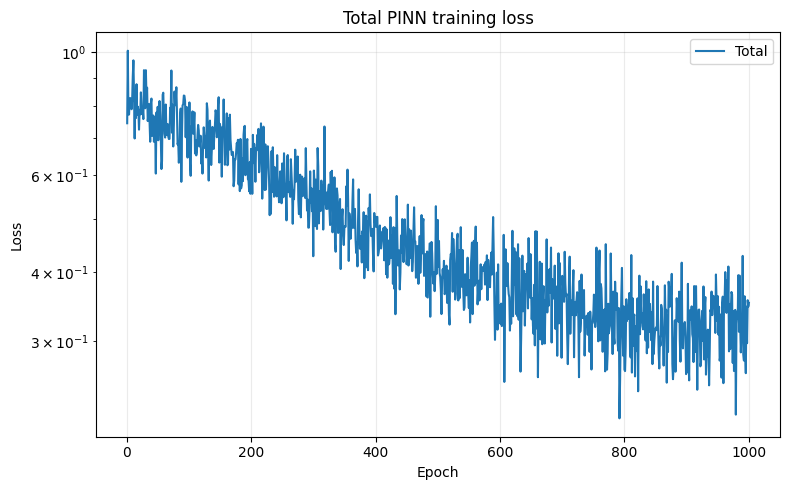

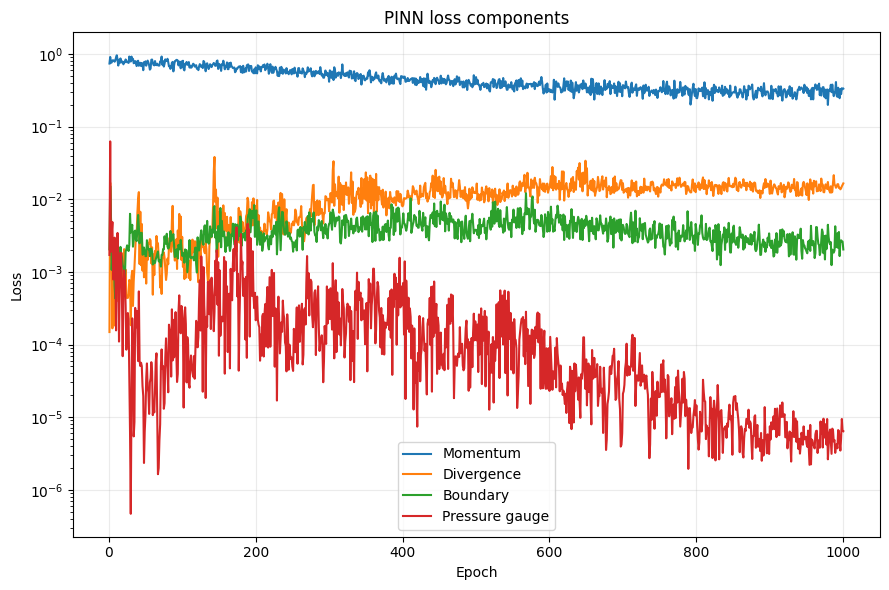

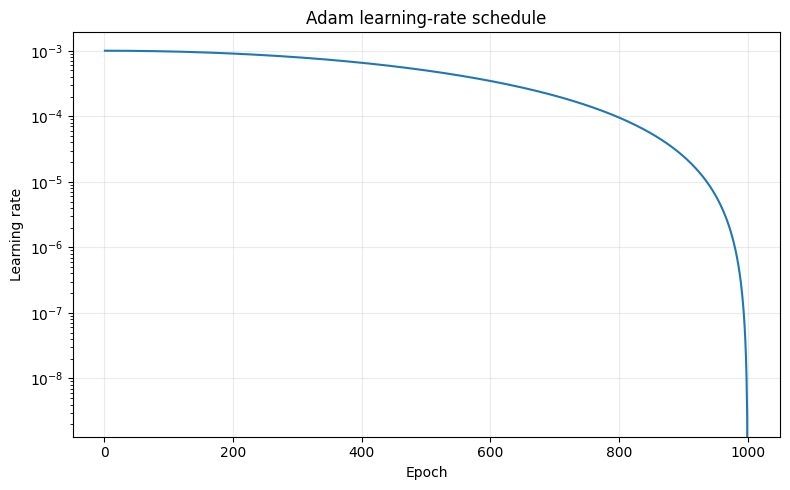

In [17]:
# ============================================================
# 16. MAIN PINN TRAINING — ADAM
# ============================================================

# ------------------------------------------------------------
# Training settings
# ------------------------------------------------------------

N_EPOCHS = 10_00

N_INTERIOR = 2_00
N_BOUNDARY = 50
N_GAUGE = 20

LR_ADAM = 1e-3


# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LR_ADAM
)


# ------------------------------------------------------------
# Learning-rate scheduler
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=N_EPOCHS
)


# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

history = {
    "total": [],
    "momentum": [],
    "divergence": [],
    "boundary": [],
    "pressure": [],
    "learning_rate": [],
}


# ------------------------------------------------------------
# Main training loop
# ------------------------------------------------------------

print("Starting main PINN training...")
print("-" * 80)

t_start = time.time()

for epoch in range(1, N_EPOCHS + 1):

    optimizer.zero_grad()


    # ========================================================
    # Compute full pure-PINN loss
    # ========================================================

    total_loss, losses = total_pinn_loss(
        model,
        n_interior=N_INTERIOR,
        n_boundary=N_BOUNDARY,
        n_gauge=N_GAUGE,
    )


    # ========================================================
    # Backpropagation
    # ========================================================

    total_loss.backward()

    optimizer.step()

    scheduler.step()


    # ========================================================
    # Store history
    # ========================================================

    history["total"].append(
        total_loss.item()
    )

    history["momentum"].append(
        losses["momentum"].item()
    )

    history["divergence"].append(
        losses["divergence"].item()
    )

    history["boundary"].append(
        losses["boundary"].item()
    )

    history["pressure"].append(
        losses["pressure"].item()
    )

    history["learning_rate"].append(
        optimizer.param_groups[0]["lr"]
    )


    # ========================================================
    # Progress output
    # ========================================================

    if (
        epoch == 1
        or epoch % 200 == 0
    ):

        print(
            f"Epoch {epoch:5d}/{N_EPOCHS} | "
            f"total = {total_loss.item():.4e} | "
            f"mom = {losses['momentum'].item():.4e} | "
            f"div = {losses['divergence'].item():.4e} | "
            f"bc = {losses['boundary'].item():.4e} | "
            f"p = {losses['pressure'].item():.4e} | "
            f"lr = {optimizer.param_groups[0]['lr']:.2e}"
        )


t_training = time.time() - t_start

print("-" * 80)
print(
    f"Adam training completed in "
    f"{t_training:.2f} s"
)

# ============================================================
# 17. PLOT PINN TRAINING HISTORY
# ============================================================

epochs = np.arange(
    1,
    len(history["total"]) + 1
)


# ------------------------------------------------------------
# Total loss
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.semilogy(
    epochs,
    history["total"],
    label="Total"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Total PINN training loss")
ax.grid(True, alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Individual loss components
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.semilogy(
    epochs,
    history["momentum"],
    label="Momentum"
)

ax.semilogy(
    epochs,
    history["divergence"],
    label="Divergence"
)

ax.semilogy(
    epochs,
    history["boundary"],
    label="Boundary"
)

ax.semilogy(
    epochs,
    history["pressure"],
    label="Pressure gauge"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("PINN loss components")
ax.grid(True, alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Learning rate
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.semilogy(
    epochs,
    history["learning_rate"]
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Learning rate")
ax.set_title("Adam learning-rate schedule")
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# MAIN PINN TRAINING — ADAM
# ============================================================

N_EPOCHS = 50000

N_INTERIOR = 10000
N_BOUNDARY = 500
N_GAUGE = 20

LR_ADAM = 1e-3


# ------------------------------------------------------------
# Loss weights
# ------------------------------------------------------------

W_MOM = 1.0
W_DIV = 10.0
W_BC = 10.0
W_PRESSURE = 1.0


# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LR_ADAM
)


# ------------------------------------------------------------
# Learning-rate scheduler
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=N_EPOCHS,
    eta_min=1e-5
)


# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

history = {
    "total": [],
    "momentum": [],
    "divergence": [],
    "boundary": [],
    "pressure": [],
    "learning_rate": [],
}


# ------------------------------------------------------------
# Main training loop
# ------------------------------------------------------------

print("Starting main PINN training...")
print("-" * 80)

t_start = time.time()

for epoch in range(1, N_EPOCHS + 1):

    optimizer.zero_grad()

    # Compute pure PINN loss
    losses = compute_pinn_losses(
        model,
        n_interior=N_INTERIOR,
        n_boundary=N_BOUNDARY,
        n_gauge=N_GAUGE,
    )

    # Weighted total loss
    total_loss = (
        W_MOM * losses["momentum"]
        + W_DIV * losses["divergence"]
        + W_BC * losses["boundary"]
        + W_PRESSURE * losses["pressure"]
    )

    # Backpropagation
    total_loss.backward()

    optimizer.step()
    scheduler.step()

    # Store history
    history["total"].append(
        total_loss.item()
    )

    history["momentum"].append(
        losses["momentum"].item()
    )

    history["divergence"].append(
        losses["divergence"].item()
    )

    history["boundary"].append(
        losses["boundary"].item()
    )

    history["pressure"].append(
        losses["pressure"].item()
    )

    history["learning_rate"].append(
        optimizer.param_groups[0]["lr"]
    )

    # Progress
    if (
        epoch == 1
        or epoch % 250 == 0
    ):

        print(
            f"Epoch {epoch:5d}/{N_EPOCHS} | "
            f"total = {total_loss.item():.4e} | "
            f"mom = {losses['momentum'].item():.4e} | "
            f"div = {losses['divergence'].item():.4e} | "
            f"bc = {losses['boundary'].item():.4e} | "
            f"p = {losses['pressure'].item():.4e} | "
            f"lr = {optimizer.param_groups[0]['lr']:.2e}"
        )


t_training = time.time() - t_start

print("-" * 80)
print(
    f"Adam training completed in "
    f"{t_training:.2f} s"
)

Starting main PINN training...
--------------------------------------------------------------------------------
Epoch     1/50000 | total = 4.7695e-01 | mom = 3.0178e-01 | div = 1.4520e-02 | bc = 2.9971e-03 | p = 6.3102e-06 | lr = 1.00e-03
Epoch   250/50000 | total = 3.9214e-01 | mom = 3.6432e-01 | div = 2.1559e-03 | bc = 6.2571e-04 | p = 6.3608e-06 | lr = 1.00e-03
Epoch   500/50000 | total = 3.4691e-01 | mom = 3.0585e-01 | div = 3.0907e-03 | bc = 1.0106e-03 | p = 4.0867e-05 | lr = 1.00e-03
Epoch   750/50000 | total = 3.0876e-01 | mom = 2.7027e-01 | div = 2.4768e-03 | bc = 8.4225e-04 | p = 5.3037e-03 | lr = 9.99e-04
Epoch  1000/50000 | total = 2.8955e-01 | mom = 2.3996e-01 | div = 3.9446e-03 | bc = 9.5305e-04 | p = 6.1810e-04 | lr = 9.99e-04
Epoch  1250/50000 | total = 2.5700e-01 | mom = 2.1720e-01 | div = 3.1578e-03 | bc = 8.2014e-04 | p = 2.8042e-05 | lr = 9.98e-04
Epoch  1500/50000 | total = 2.4213e-01 | mom = 1.9678e-01 | div = 3.8231e-03 | bc = 6.5503e-04 | p = 5.6620e-04 | lr = 9

KeyboardInterrupt: 

In [ ]:
------------------------------------------------ prove

<>:127: SyntaxWarning: invalid escape sequence '\m'
<>:127: SyntaxWarning: invalid escape sequence '\m'
<>:127: SyntaxWarning: invalid escape sequence '\m'
<>:127: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2537/3321758871.py:127: SyntaxWarning: invalid escape sequence '\m'
  fig.suptitle(f"{prefix} | idx={idx}, $\mu_0$={mu0v:.3f}, $\mu_1$={mu1v:.3f}", fontsize=12, fontweight='bold', y=0.98)
/tmp/ipykernel_2537/3321758871.py:127: SyntaxWarning: invalid escape sequence '\m'
  fig.suptitle(f"{prefix} | idx={idx}, $\mu_0$={mu0v:.3f}, $\mu_1$={mu1v:.3f}", fontsize=12, fontweight='bold', y=0.98)


Indice Best Case: 9 (Errore Totale: 4.36e-01)
Indice Worst Case: 35 (Errore Totale: 1.39e+00)


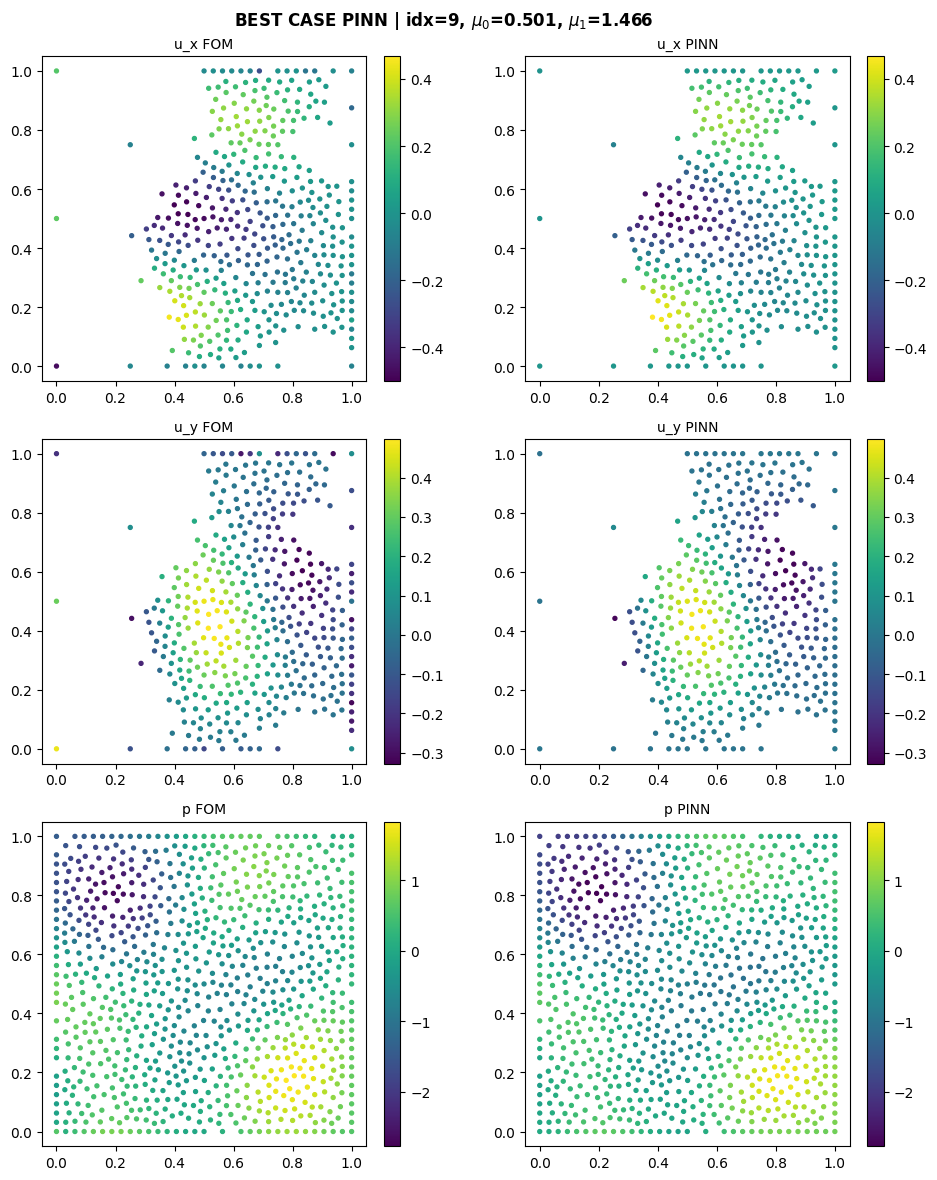

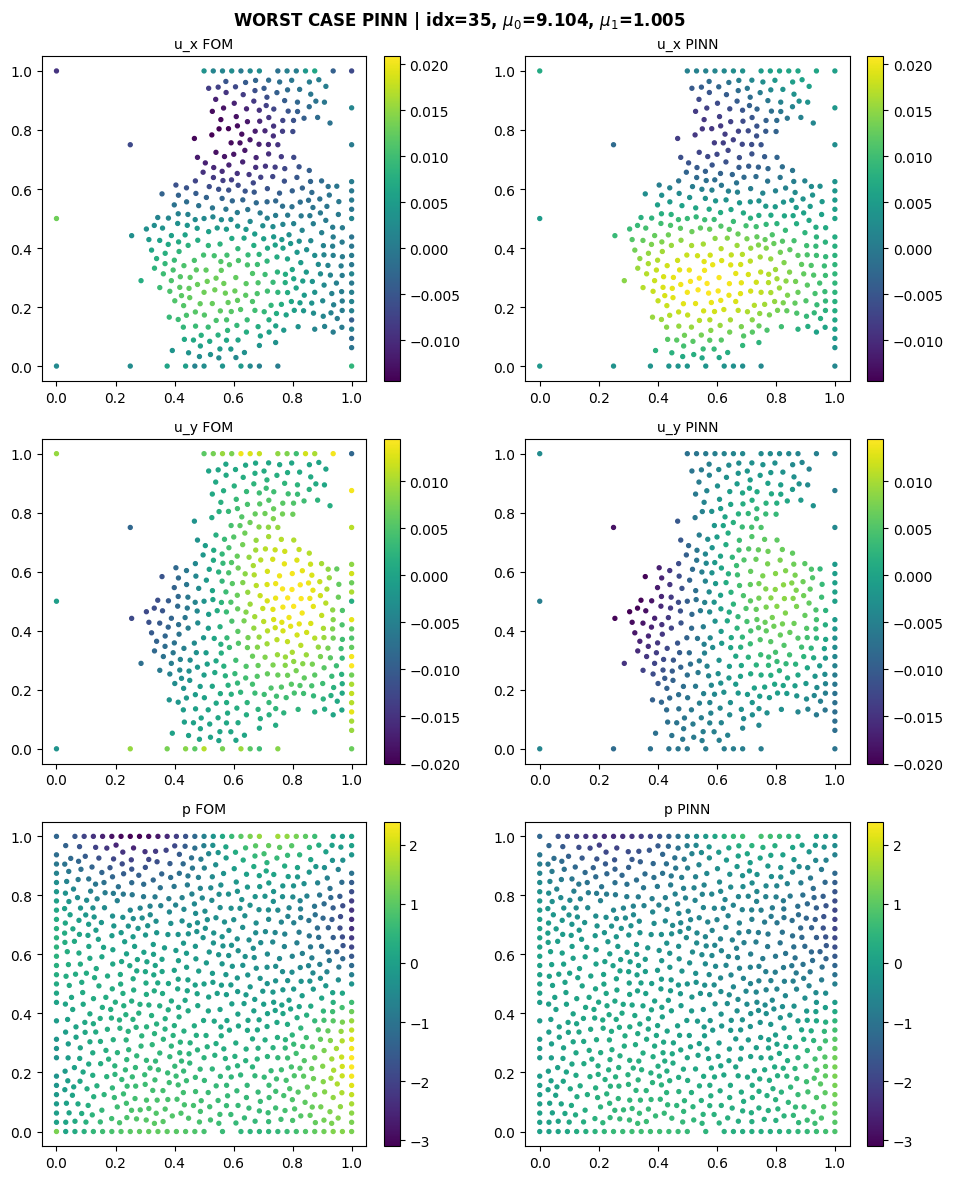

In [46]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

# 1. Caricamento dei dati FOM e delle coordinate PINN
DATA_DIR = os.path.join(PROJECT_DIR, "data", "fom")

test_parameters = np.load(os.path.join(DATA_DIR, "test_parameters.npy"))
test_snapshots  = np.load(os.path.join(DATA_DIR, "test_snapshots.npy"))

pinn_coordinates      = np.load(os.path.join(DATA_DIR, "pinn_coordinates.npy"))
pinn_pressure_indices = np.load(os.path.join(DATA_DIR, "pinn_pressure_indices.npy"))
pinn_velocity_indices = np.load(os.path.join(DATA_DIR, "pinn_velocity_indices.npy"))
mesh_info = np.load(os.path.join(DATA_DIR, "mesh_info.npy"), allow_pickle=True).item()

speed_n_dofs    = mesh_info["speed_n_dofs"]
pressure_n_dofs = mesh_info["pressure_n_dofs"]

x_coords = pinn_coordinates[:, 0]
y_coords = pinn_coordinates[:, 1]
N_nodes = len(pinn_coordinates)

# 2. Calcolo rapido degli errori sui test set per trovare best e worst case
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.eval()

half_vel = len(pinn_velocity_indices) // 2

with torch.no_grad():
    x_t = torch.tensor(x_coords, dtype=torch.float32).unsqueeze(1).to(device)
    y_t = torch.tensor(y_coords, dtype=torch.float32).unsqueeze(1).to(device)

    errors_u = []
    errors_p = []

    for i in range(len(test_parameters)):
        mu0_val = test_parameters[i, 0]
        mu1_val = test_parameters[i, 1]

        mu0_t = torch.full_like(x_t, mu0_val)
        mu1_t = torch.full_like(x_t, mu1_val)

        # Il modello restituisce un tensore unico (N, 3)
        preds = model(x_t, y_t, mu0_t, mu1_t)

        u1_p = preds[:, 0].cpu().numpy().flatten()
        u2_p = preds[:, 1].cpu().numpy().flatten()
        p_p  = preds[:, 2].cpu().numpy().flatten()

        snapshot = test_snapshots[i]

        u1_fem = snapshot[pinn_velocity_indices[:half_vel]]
        u2_fem = snapshot[speed_n_dofs + pinn_velocity_indices[:half_vel]]
        p_fem  = snapshot[2 * speed_n_dofs + pinn_pressure_indices[:len(p_p)]]

        u1_p_sub = u1_p[:half_vel]
        u2_p_sub = u2_p[:half_vel]
        p_p_sub  = p_p[:len(p_fem)]

        vel_fem_norm = np.linalg.norm(np.sqrt(u1_fem**2 + u2_fem**2))
        vel_pinn_diff = np.linalg.norm(np.sqrt((u1_p_sub - u1_fem)**2 + (u2_p_sub - u2_fem)**2))
        err_u = vel_pinn_diff / (vel_fem_norm + 1e-8)

        err_p = np.linalg.norm(p_p_sub - p_fem) / (np.linalg.norm(p_fem) + 1e-8)

        errors_u.append(err_u)
        errors_p.append(err_p)

# Identificazione indici best e worst
errors_u = np.array(errors_u)
errors_p = np.array(errors_p)
total_errors = errors_u + errors_p

best = np.argmin(total_errors)
worst = np.argmax(total_errors)

print(f"Indice Best Case: {best} (Errore Totale: {total_errors[best]:.2e})")
print(f"Indice Worst Case: {worst} (Errore Totale: {total_errors[worst]:.2e})")

# 3. Preparazione variabili globali per il plot
x_base = torch.tensor(x_coords, dtype=torch.float32).unsqueeze(1).to(device)
y_base = torch.tensor(y_coords, dtype=torch.float32).unsqueeze(1).to(device)

test_ux = test_snapshots[:, pinn_velocity_indices[:half_vel]]
test_uy = test_snapshots[:, speed_n_dofs + pinn_velocity_indices[:half_vel]]
test_p  = test_snapshots[:, 2 * speed_n_dofs + pinn_pressure_indices]

# 4. Funzione di plotting Best / Worst Case
def plot_case(idx, prefix=""):
    mu0v = float(test_parameters[idx, 0])
    mu1v = float(test_parameters[idx, 1])

    mu0_t = torch.full((N_nodes, 1), mu0v, dtype=torch.float32, device=device)
    mu1_t = torch.full((N_nodes, 1), mu1v, dtype=torch.float32, device=device)

    model.eval()
    with torch.no_grad():
        preds = model(x_base, y_base, mu0_t, mu1_t)

    ux = preds[:, 0].cpu().numpy().flatten()[:half_vel]
    uy = preds[:, 1].cpu().numpy().flatten()[:half_vel]
    p  = preds[:, 2].cpu().numpy().flatten()[:test_p.shape[1]]

    x_sub = pinn_coordinates[:half_vel, 0]
    y_sub = pinn_coordinates[:half_vel, 1]

    x_p_sub = pinn_coordinates[:len(p), 0]
    y_p_sub = pinn_coordinates[:len(p), 1]

    fig, axes = plt.subplots(3, 2, figsize=(10, 12))
    pairs = [
        (test_ux[idx], ux, "u_x FOM", "u_x PINN", x_sub, y_sub),
        (test_uy[idx], uy, "u_y FOM", "u_y PINN", x_sub, y_sub),
        (test_p[idx],  p,  "p FOM",   "p PINN",   x_p_sub, y_p_sub),
    ]

    for r, (fom, pr, t1, t2, x_coords_use, y_coords_use) in enumerate(pairs):
        vmin = min(fom.min(), pr.min())
        vmax = max(fom.max(), pr.max())
        for c, (data, tt) in enumerate([(fom, t1), (pr, t2)]):
            sc = axes[r, c].scatter(x_coords_use, y_coords_use, c=data, s=8, vmin=vmin, vmax=vmax, cmap="viridis")
            axes[r, c].set_title(f"{tt}", fontsize=10)
            axes[r, c].set_aspect("equal")
            fig.colorbar(sc, ax=axes[r, c], fraction=0.046, pad=0.04)

    fig.suptitle(f"{prefix} | idx={idx}, $\mu_0$={mu0v:.3f}, $\mu_1$={mu1v:.3f}", fontsize=12, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.savefig(f"pinn_{prefix.lower().replace(' ', '_')}.png", dpi=300, bbox_inches='tight')
    plt.show()

# Esecuzione dei plot
plot_case(best,  "BEST CASE PINN")
plot_case(worst, "WORST CASE PINN")

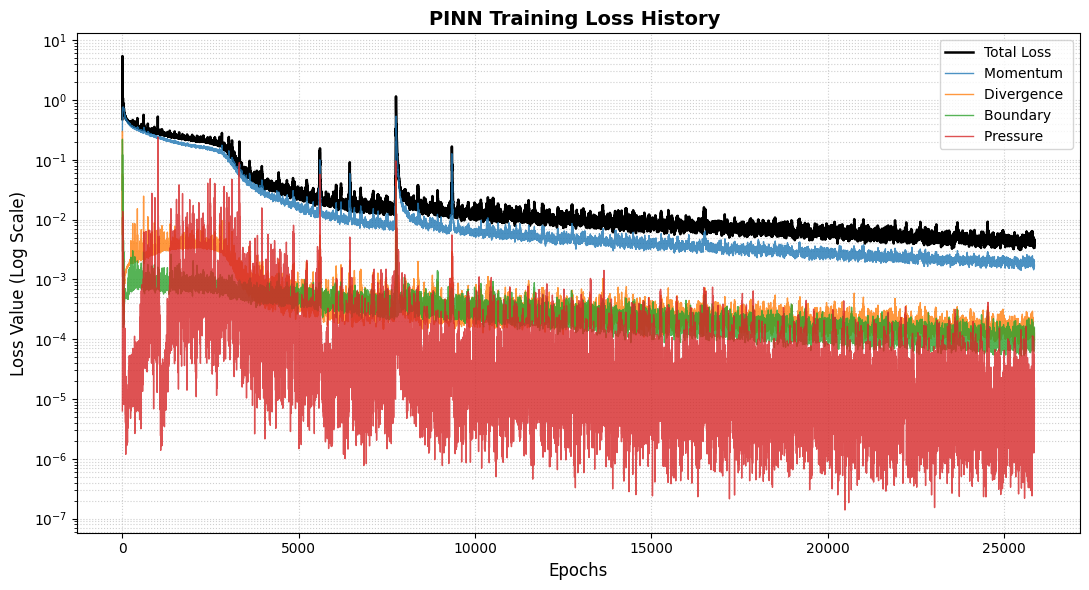

In [50]:
import matplotlib.pyplot as plt

# Definiamo l'asse delle epoche in base ai dati effettivamente salvati in history
epochs = range(1, len(history["total"]) + 1)

plt.figure(figsize=(11, 6))

# Plot della Loss Totale (in neretto e nero per evidenziarla)
plt.plot(epochs, history["total"], label='Total Loss', color='black', linewidth=1.8)

# Plot delle singole componenti fisiche e al contorno
plt.plot(epochs, history["momentum"], label='Momentum ', alpha=0.8, linewidth=1)
plt.plot(epochs, history["divergence"], label='Divergence ', alpha=0.8, linewidth=1)
plt.plot(epochs, history["boundary"], label='Boundary ', alpha=0.8, linewidth=1)
plt.plot(epochs, history["pressure"], label='Pressure ', alpha=0.8, linewidth=1)

# Impostazioni di scala e grafica
plt.yscale('log')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss Value (Log Scale)', fontsize=12)
plt.title('PINN Training Loss History ', fontsize=14, fontweight='bold')

# Legenda, griglia e salvataggio
plt.legend(fontsize=10, loc='upper right', frameon=True)
plt.grid(True, which="both", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig('pinn_loss.png', dpi=300, bbox_inches='tight')
plt.show()